# 03 — Concentration: how much of a year's value sits in a handful of intervals?

**Method:** for each region and financial year, sort the 5-minute intervals from highest to lowest price and add up
their **value** = price × energy (RRP × TOTALDEMAND × 5/60 h, in $). The cumulative share of value tells you how much
of the year's wholesale energy cost came from the most expensive intervals.

- A year has ~105,000 intervals per region, so the **top 1% ≈ 1,050 intervals ≈ 88 hours** and the **top 0.1% ≈ 105 intervals ≈ 9 hours**
- **Value is net**: negative-price intervals subtract from the total. That's why the curve can climb *above* 100% and come back down to exactly 100% at the end
- Complete FYs only on the chart (FY23–FY26); FY22 (from Oct) and FY27 (Jul–Sep) appear in the tables, flagged as partial
- The June 2022 suspension is excluded

**This is the headline chart.** It backs the interview line: *most of the year's value sits in a handful of intervals.*

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

sys.path.append("../src")
from chart_style import apply_style, save_chart, FY_COLOR, SURFACE, INK, INK_2, MUTED, AXIS

apply_style()
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_parquet("../data/clean/nem_5min.parquet")
df = df[~df["is_suspension"]].copy()

df["mwh"] = df["TOTALDEMAND"] * 5 / 60   # energy in the interval: MW x 5 minutes
df["value"] = df["RRP"] * df["mwh"]      # $ paid for that energy at the spot price

COMPLETE_FY = ["FY23", "FY24", "FY25", "FY26"]
PARTIAL_FY = {"FY22": "Oct–Jun only", "FY27": "Jul–Sep only"}

## 1. Headline numbers

In [2]:
def top_share(g, pct):
    """Share of the group's total value that comes from its top `pct` of intervals by price."""
    n = int(round(len(g) * pct))
    return g.nlargest(n, "RRP")["value"].sum() / g["value"].sum()


def concentration_stats(g):
    above_300 = g["RRP"] > 300
    return pd.Series({
        "intervals": len(g),
        "total_value_$m": g["value"].sum() / 1e6,
        "demand_weighted_price": g["value"].sum() / g["mwh"].sum(),
        "top_0.1%_share": top_share(g, 0.001),
        "top_1%_share": top_share(g, 0.01),
        "top_1%_threshold_price": g["RRP"].quantile(0.99),
        "hours_above_300": above_300.sum() * 5 / 60,
        "value_above_300_share": g.loc[above_300, "value"].sum() / g["value"].sum(),
        # What a $300 cap contract pays out: (price - 300) on every MWh, only when price > 300
        "cap_payout_share": ((g["RRP"] - 300).clip(lower=0) * g["mwh"]).sum() / g["value"].sum(),
    })


stats = df.groupby(["REGIONID", "fy"])[["RRP", "mwh", "value"]].apply(concentration_stats)
stats["note"] = stats.index.get_level_values("fy").map(PARTIAL_FY).fillna("")

pct_cols = ["top_0.1%_share", "top_1%_share", "value_above_300_share", "cap_payout_share"]
stats.style.format({c: "{:.1%}" for c in pct_cols} | {
    "intervals": "{:,.0f}", "total_value_$m": "{:,.0f}", "demand_weighted_price": "{:,.2f}",
    "top_1%_threshold_price": "{:,.0f}", "hours_above_300": "{:,.1f}",
})

**How to read the columns**
- `top_1%_share` — share of the FY's energy cost that came from its most expensive 1% of intervals (~88 hours)
- `top_1%_threshold_price` — the price you need to be in the top 1%
- `value_above_300_share` — share of the cost from intervals priced above $300
- `cap_payout_share` — what a $300 cap would have paid back, as a share of the whole year's cost. This is the protection a retailer buys

## 2. The concentration curve

x-axis is **log scale** so the top 0.1% and 1% get room; on a linear axis they'd be a sliver at the left edge.
The dashed line is what the curve would look like if every interval had the same value.

In [3]:
def concentration_curve(g):
    """Cumulative share of value vs share of intervals, intervals sorted from highest price."""
    g = g.sort_values("RRP", ascending=False)
    return pd.DataFrame({
        "share_of_intervals": np.arange(1, len(g) + 1) / len(g),
        "share_of_value": (g["value"].cumsum() / g["value"].sum()).to_numpy(),
    })


curves = (
    df[df["fy"].isin(COMPLETE_FY)]
    .groupby(["REGIONID", "fy"])[["RRP", "value"]]
    .apply(concentration_curve)
)
curves.head()

share_of_intervals  share_of_value
REGIONID fy                                        
NSW1     FY23 0                0.00            0.00
              1                0.00            0.00
              2                0.00            0.00
              3                0.00            0.00
              4                0.00            0.01

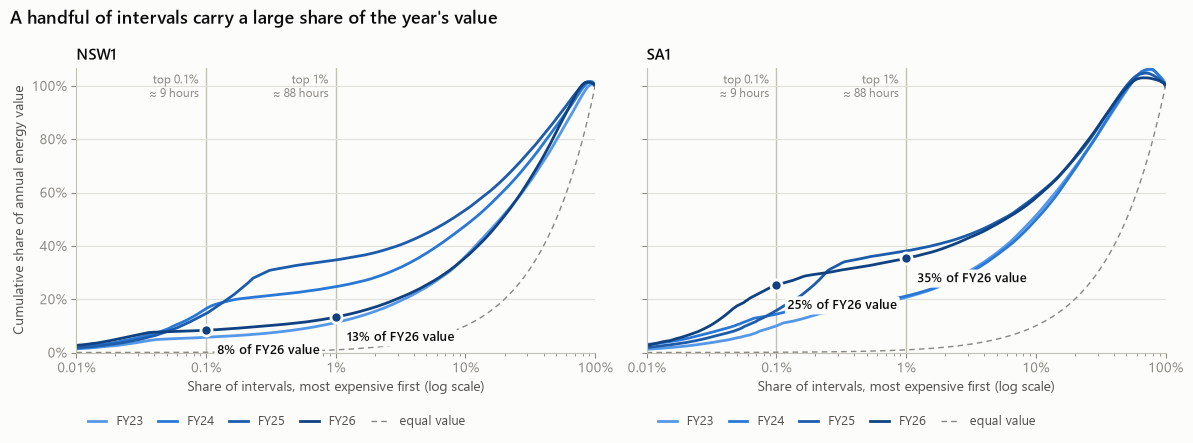

In [4]:
MARKS = [  # (share of intervals, stats column, axis label)
    (0.001, "top_0.1%_share", "top 0.1%\n≈ 9 hours"),
    (0.01, "top_1%_share", "top 1%\n≈ 88 hours"),
]


def plot_concentration(regions=("NSW1", "SA1"), highlight_fy="FY26"):
    fig, axes = plt.subplots(1, len(regions), figsize=(6 * len(regions), 4.6), sharey=True, squeeze=False)

    for ax, region in zip(axes.flat, regions):
        for fy in COMPLETE_FY:
            c = curves.loc[(region, fy)]
            ax.plot(c["share_of_intervals"], c["share_of_value"], color=FY_COLOR[fy], lw=2, label=fy)

        # If every interval were worth the same, share of value = share of intervals
        x = np.logspace(-4, 0, 200)
        ax.plot(x, x, color=MUTED, lw=1, ls=(0, (4, 3)), label="equal value")

        # Mark the top 0.1% and 1%, and label the highlighted FY's value at each
        for pct, column, label in MARKS:
            share = stats.loc[(region, highlight_fy), column]
            ax.axvline(pct, color=AXIS, lw=1, zorder=0)
            ax.text(pct * 0.88, 0.98, label, transform=ax.get_xaxis_transform(),
                    color=MUTED, fontsize=8.5, ha="right", va="top")
            ax.plot(pct, share, "o", ms=8, color=FY_COLOR[highlight_fy], mec=SURFACE, mew=2, zorder=5)
            ax.annotate(f"{share:.0%} of {highlight_fy} value", (pct, share), xytext=(8, -10),
                        textcoords="offset points", ha="left", va="top", fontsize=9.5, color=INK,
                        fontweight="semibold", zorder=6,
                        bbox=dict(boxstyle="round,pad=0.2", fc=SURFACE, ec="none"))

        ax.set_xscale("log")
        ax.set_xlim(1e-4, 1)
        ax.set_ylim(0, None)
        ax.set_xticks([1e-4, 1e-3, 1e-2, 1e-1, 1], ["0.01%", "0.1%", "1%", "10%", "100%"])
        ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set_title(region)
        ax.set_xlabel("Share of intervals, most expensive first (log scale)")
        ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, ncol=5, handlelength=1.5, columnspacing=1.2,
                  loc="upper left", bbox_to_anchor=(0, -0.18))
    axes[0, 0].set_ylabel("Cumulative share of annual energy value")

    fig.suptitle("A handful of intervals carry a large share of the year's value",
                 x=0.01, ha="left", fontsize=13, fontweight="semibold")
    fig.tight_layout()
    return fig


fig = plot_concentration()
save_chart(fig, "../charts/03_concentration.png")

**What it shows:** _your sentence_

**Why it matters to a trader:** _your sentence_

## 3. Top-1% share by year

In [5]:
share_table = stats[["top_0.1%_share", "top_1%_share", "cap_payout_share"]].unstack("REGIONID")
share_table.style.format("{:.1%}")

## 4. The interview line, with your numbers

Fill in from the tables above (FY26 is the latest complete year):

> *"In FY__, __% of NSW's wholesale energy value came from the most expensive 1% of intervals — about 88 hours.
> In SA it was __%. A $300 cap would have paid back __% of the year's cost. That's why retailers buy caps
> and why a battery that's only available for those hours can still make money."*

## Try it yourself

- Change `pct` in `top_share` to 5% or 10%: where does the concentration flatten out?
- Change the cap strike from 300 to 500 in `concentration_stats`: how much protection is lost?
- Re-run including the suspension (remove the `is_suspension` filter): how much does FY22 change?